# Laboratory 1 — The discrete signal: spectral analysis and filtering of a noisy recording

**Objective.** Two recordings of 120 s contain noise you can hear — and maybe a signal. Find the signal, describe the noise,
remove the 50 Hz mains hum, and bring the signal back with filters built in Fourier space (band-pass, comb, Wiener).
Check every filter against the clean signal.

**Data** (`data/`): `dati_rumorosi.wav`, `dati_rumorosi_2.wav` (the noisy recordings) and `segnale.wav`, `segnale_2.wav`
(the noise-free signals, same scale, used only to *check* the filters). Each file: 120 s, 44.1 kHz, 16-bit, mono.

**Workflow.** 0 read & look → 1 periodogram & Welch → 2 stationarity (STFT) → 3 band-pass → 4 comb →
5 noise fit → 6 Wiener (naive, then on detected lines) → 7 Whittle fit → recording 2 → summary.

*Corrected and extended version of `AstroSignal.ipynb`: see the last cell for the list of fixes.*

## Block 0 — Setup: libraries, data folder, helper functions

In [1]:
import os
import numpy as np
import scipy.signal as sp
from scipy.io import wavfile
from scipy.fft import rfft, irfft, rfftfreq
from scipy.ndimage import median_filter
from scipy.optimize import curve_fit, minimize
import matplotlib.pyplot as plt

# Data: in Google Colab upload the four WAV files once; locally, keep them in ./data
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
os.makedirs('data', exist_ok=True)
NAMES = ['dati_rumorosi.wav', 'segnale.wav', 'dati_rumorosi_2.wav', 'segnale_2.wav']
if IN_COLAB and not all(os.path.exists(os.path.join('data', n)) for n in NAMES):
    from google.colab import files
    for fn in files.upload():                      # select the four .wav files
        os.replace(fn, os.path.join('data', fn))

os.makedirs('figures', exist_ok=True)              # every figure is also saved as PNG
os.makedirs('out_wav', exist_ok=True)              # filtered recordings
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

HUM = 50.0                                         # mains hum [Hz]: instrumental, NOT signal

def read_wav(name):
    # int16 -> float64: sums and squares of int16 overflow at 32767
    fs, x = wavfile.read(os.path.join('data', name))
    return fs, x.astype(np.float64)

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join('figures', name + '.png'), dpi=110)
    plt.show()

def snr_db(y, s):
    # signal-to-noise ratio of a filtered signal y against the clean signal s
    return 10 * np.log10(np.var(s) / np.var(y - s))

def note_name(f):
    # nearest equal-tempered note and its offset in cents (A4 = 440 Hz)
    n = 12 * np.log2(f / 440.0)
    k = int(np.round(n))
    names = ['A', 'A#', 'B', 'C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#']
    octave = 4 + (k + 9) // 12
    return f"{names[k % 12]}{octave} ({100 * (n - k):+.0f} cents)"

def write_wav(name, y, fs):
    # scale to full scale (arbitrary units) and save as 16-bit
    wavfile.write(os.path.join('out_wav', name), fs, np.int16(y / np.abs(y).max() * 32767))

print('Colab' if IN_COLAB else 'local', '| files:', sorted(os.listdir('data')))

local | files: ['dati_rumorosi.wav', 'dati_rumorosi_2.wav', 'segnale.wav', 'segnale_2.wav']


## Block 1 — Read the recordings and the clean references

In [2]:
fs, x = read_wav('dati_rumorosi.wav')     # recording 1 (noisy)
fs_s, s = read_wav('segnale.wav')          # its clean signal (only for checking)
assert fs_s == fs                          # do not overwrite fs with the second read
N = x.size
T = N / fs
t = np.arange(N) / fs                      # sample times n/fs
z = (t > 60) & (t < 60.02)                 # a 20 ms window used for every comparison
t_ms = (t[z] - 60) * 1e3

print(f"{'quantity':<28}{'value':>16}")
print('-' * 44)
for k, v in [('sampling rate fs [Hz]', fs), ('samples N', N), ('duration T [s]', T),
             ('resolution 1/T [Hz]', f'{1 / T:.4f}'), ('rms of the data', f'{x.std():.0f}'),
             ('peak |x| (int16 max 32767)', f'{np.abs(x).max():.0f}'),          # max() needs ()
             ('rms of the clean signal', f'{s.std():.1f}'),
             ('signal / noise power [dB]', f'{10 * np.log10(s.var() / (x - s).var()):.1f}')]:
    print(f"{k:<28}{v:>16}")

quantity                               value
--------------------------------------------


sampling rate fs [Hz]                  44100
samples N                            5292000
duration T [s]                         120.0
resolution 1/T [Hz]                   0.0083
rms of the data                        13194
peak |x| (int16 max 32767)             29490
rms of the clean signal                 73.4
signal / noise power [dB]              -45.1


## Block 2 — Look at the samples (before any processing)

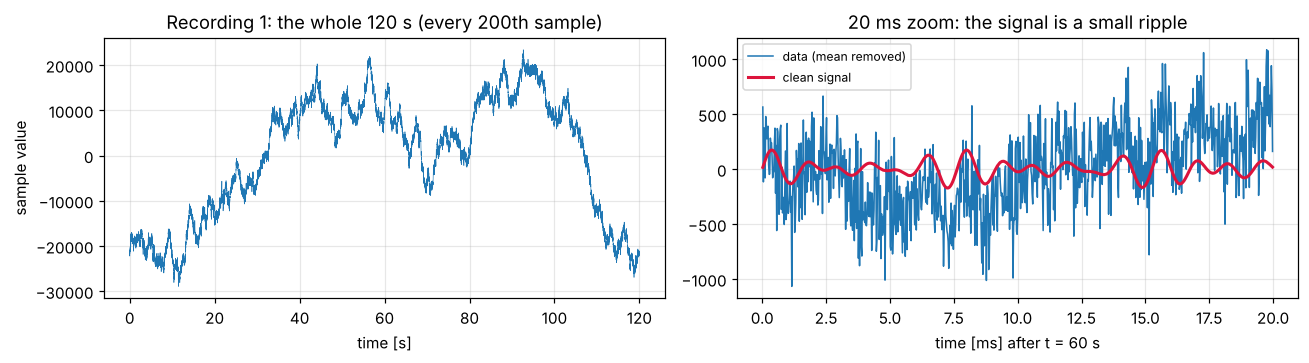

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(t[::200], x[::200], lw=0.4)
ax[0].set(xlabel='time [s]', ylabel='sample value', title='Recording 1: the whole 120 s (every 200th sample)')
ax[1].plot(t_ms, x[z] - x[z].mean(), lw=1, label='data (mean removed)')
ax[1].plot(t_ms, s[z], lw=2, color='crimson', label='clean signal')
ax[1].set(xlabel='time [ms] after t = 60 s', title='20 ms zoom: the signal is a small ripple')
ax[1].legend(fontsize=8)
savefig('b02_time_domain')

## Block 3 — Periodogram and Welch

Welch: L = 65536 samples (1.49 s), bins of 0.673 Hz, K = 160 segments; Bartlett K = 80


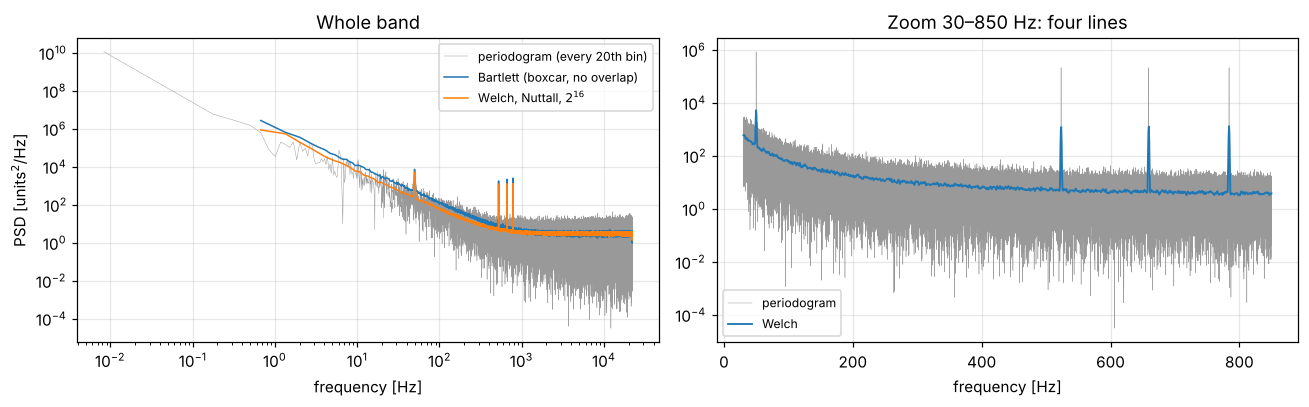

In [4]:
fp, P = sp.periodogram(x, fs)                                  # one-sided PSD, whole record
L = 2**16                                                      # 1.49 s segments
fw, W = sp.welch(x, fs, window='nuttall', nperseg=L)           # 50% overlap (default)
fb, B = sp.welch(x, fs, window='boxcar', nperseg=L, noverlap=0)  # Bartlett
K = (N - L) // (L // 2) + 1
print(f"Welch: L = {L} samples ({L/fs:.2f} s), bins of {fs/L:.3f} Hz, K = {K} segments; Bartlett K = {N // L}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].loglog(fp[1::20], P[1::20], lw=0.3, color='0.6', label='periodogram (every 20th bin)')
ax[0].loglog(fb[1:], B[1:], lw=1, label='Bartlett (boxcar, no overlap)')
ax[0].loglog(fw[1:], W[1:], lw=1, label='Welch, Nuttall, $2^{16}$')
ax[0].set(xlabel='frequency [Hz]', ylabel='PSD [units$^2$/Hz]', title='Whole band')
ax[0].legend(fontsize=8)
band = (fp > 30) & (fp < 850)
ax[1].semilogy(fp[band], P[band], lw=0.3, color='0.6', label='periodogram')
ax[1].semilogy(fw[(fw > 30) & (fw < 850)], W[(fw > 30) & (fw < 850)], lw=1.2, label='Welch')
ax[1].set(xlabel='frequency [Hz]', title='Zoom 30–850 Hz: four lines')
ax[1].legend(fontsize=8)
savefig('b03_periodogram_welch')

## Block 4 — Find the lines automatically and name them

In [5]:
floor = median_filter(W, size=201, mode='nearest')             # local noise level (135 Hz)
peaks, _ = sp.find_peaks(W / floor, height=20)
peaks = peaks[fw[peaks] > 20]
peaks = np.union1d(peaks, [np.argmin(np.abs(fw - HUM))])     # the hum sits on a steep slope: add it
peaks = peaks[np.argsort(fw[peaks])]
print(f"{'f [Hz]':>9} {'Welch/floor':>12} {'periodogram contrast':>21}   nature")
for k in peaks:
    m = (fp > fw[k] - 1) & (fp < fw[k] + 1)
    jj = np.flatnonzero(m)[np.argmax(P[m])]                    # exact periodogram bin (0.008 Hz)
    ring = (np.abs(fp - fp[jj]) > 2) & (np.abs(fp - fp[jj]) < 20)
    contrast_p = P[jj] / (np.median(P[ring]) / np.log(2))      # median of an exponential = ln2 x mean
    kind = 'mains hum (instrument)' if abs(fw[k] - HUM) < 1 else note_name(fp[jj])
    print(f"{fp[jj]:9.2f} {W[k] / floor[k]:12.0f} {contrast_p:21.0f}   {kind}")
lines = [523.3, 659.3, 784.0]                                  # C5, E5, G5: a C major chord
lines_all = [HUM] + lines

   f [Hz]  Welch/floor  periodogram contrast   nature
    50.00           19                  3469   mains hum (instrument)
   523.30          238                 41623   C5 (+0 cents)
   659.30          291                 48593   E5 (+0 cents)
   784.00          335                 54067   G5 (+0 cents)


## Block 5 — Which window? Leakage and line contrast (table)

window           noise/ref 50-100 Hz  500-1000 Hz  contrast C5      E5      G5


boxcar                          2.13         1.31          219     364     499


triang                          1.05         1.01          314     412     495


hamming                         1.08         1.01          309     402     482


hann                            1.06         1.01          292     373     439


blackmanharris                  1.05         1.00          235     286     330


nuttall                         1.05         1.00          238     291     335


flattop                         1.07         1.00          139     158     179


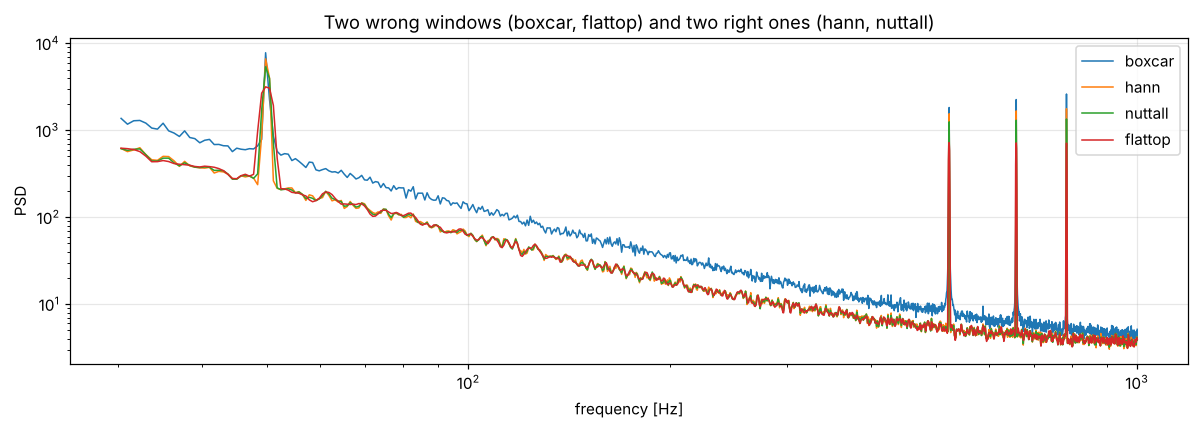

In [6]:
fr, Wref = sp.welch(x, fs, window='nuttall', nperseg=2**18)   # reference: long Nuttall
def level(fq, Wq, lo, hi):
    m = (fq > lo) & (fq < hi) & np.all(np.abs(fq[:, None] - np.array(lines_all)) > 5, axis=1)
    return np.median(Wq[m])

print(f"{'window':<16}{'noise/ref 50-100 Hz':>20}{'500-1000 Hz':>13}{'contrast C5':>13}{'E5':>8}{'G5':>8}")
rows = {}
fig, ax = plt.subplots(figsize=(11, 4))
for win in ['boxcar', 'triang', 'hamming', 'hann', 'blackmanharris', 'nuttall', 'flattop']:
    fq, Wq = sp.welch(x, fs, window=win, nperseg=L)
    fl = median_filter(Wq, size=201, mode='nearest')
    con = [Wq[np.argmin(np.abs(fq - l))] / fl[np.argmin(np.abs(fq - l))] for l in lines]
    rows[win] = (level(fq, Wq, 50, 100) / level(fr, Wref, 50, 100), level(fq, Wq, 500, 1000) / level(fr, Wref, 500, 1000), *con)
    print(f"{win:<16}{rows[win][0]:20.2f}{rows[win][1]:13.2f}{con[0]:13.0f}{con[1]:8.0f}{con[2]:8.0f}")
    if win in ('boxcar', 'flattop', 'hann', 'nuttall'):
        m = (fq > 30) & (fq < 1000)
        ax.loglog(fq[m], Wq[m], lw=1, label=win)
ax.set(xlabel='frequency [Hz]', ylabel='PSD', title='Two wrong windows (boxcar, flattop) and two right ones (hann, nuttall)')
ax.legend()
savefig('b05_windows')

## Block 6 — How long should the segments be? (table)

        L  duration [s]  bin [Hz]     K  contrast C5       E5       G5


     4096          0.09    10.767  2582           14       18       20


    16384          0.37     2.692   644           55       75       79


    65536          1.49     0.673   160          238      291      335


   262144          5.94     0.168    39          954     1221     1242


  1048576         23.78     0.042     9         3860     4644     5083


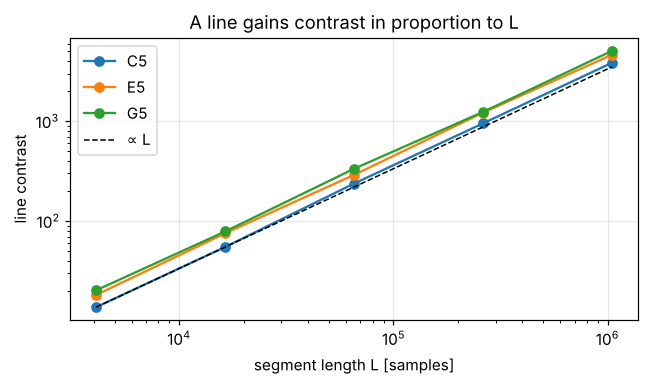

In [7]:
print(f"{'L':>9} {'duration [s]':>13} {'bin [Hz]':>9} {'K':>5} {'contrast C5':>12} {'E5':>8} {'G5':>8}")
Ls, cons = [], []
for q in [12, 14, 16, 18, 20]:
    Lq = 2**q
    fq, Wq = sp.welch(x, fs, window='nuttall', nperseg=Lq)
    fl = median_filter(Wq, size=max(21, int(135 / (fs / Lq)) | 1), mode='nearest')
    con = [Wq[np.argmin(np.abs(fq - l))] / fl[np.argmin(np.abs(fq - l))] for l in lines]
    Ls.append(Lq); cons.append(con)
    print(f"{Lq:9d} {Lq/fs:13.2f} {fs/Lq:9.3f} {(N - Lq)//(Lq//2) + 1:5d} {con[0]:12.0f} {con[1]:8.0f} {con[2]:8.0f}")
plt.figure(figsize=(6, 3.6))
plt.loglog(Ls, np.array(cons), 'o-')
plt.loglog(Ls, cons[0][0] * np.array(Ls) / Ls[0], 'k--', lw=1, label='∝ L')
plt.xlabel('segment length L [samples]'); plt.ylabel('line contrast'); plt.legend(['C5', 'E5', 'G5', '∝ L'])
plt.title('A line gains contrast in proportion to L')
savefig('b06_contrast_vs_L')

## Block 7 — Is the signal stationary? Spectrogram and amplitude in 10 s blocks

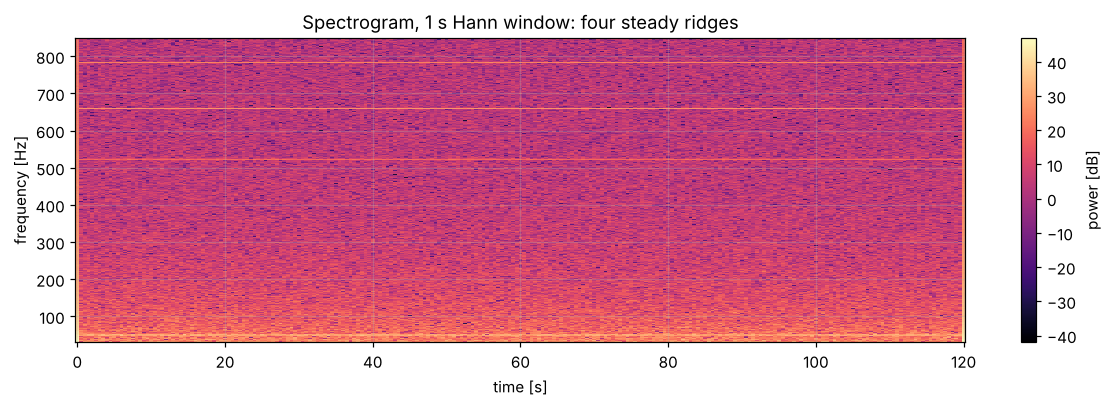

 line [Hz]  mean amplitude     std  std/mean
      50.0           120.2     7.7      6.4%


     523.3            60.1     1.1      1.8%
     659.3            60.0     0.8      1.3%


     784.0            60.0     0.8      1.4%


In [8]:
fq, tt, Z = sp.stft(x, fs, window='hann', nperseg=fs, noverlap=fs // 2)   # 1 s window
band = (fq > 30) & (fq < 850)
plt.figure(figsize=(11, 3.8))
plt.pcolormesh(tt, fq[band], 10 * np.log10(np.abs(Z[band])**2 + 1e-12), shading='auto', cmap='magma')
plt.colorbar(label='power [dB]')
plt.xlabel('time [s]'); plt.ylabel('frequency [Hz]'); plt.title('Spectrogram, 1 s Hann window: four steady ridges')
savefig('b07_spectrogram')

print(f"{'line [Hz]':>10} {'mean amplitude':>15} {'std':>7} {'std/mean':>9}")
blk = int(10 * fs)
for fl in lines_all:
    amps = [2 * np.abs(np.sum(x[i:i+blk] * np.exp(-2j * np.pi * fl * t[i:i+blk]))) / blk for i in range(0, N - blk + 1, blk)]
    print(f"{fl:10.1f} {np.mean(amps):15.1f} {np.std(amps):7.1f} {np.std(amps)/np.mean(amps):9.1%}")

## Block 8 — Filtering in Fourier space; band-pass by eye (before / after)

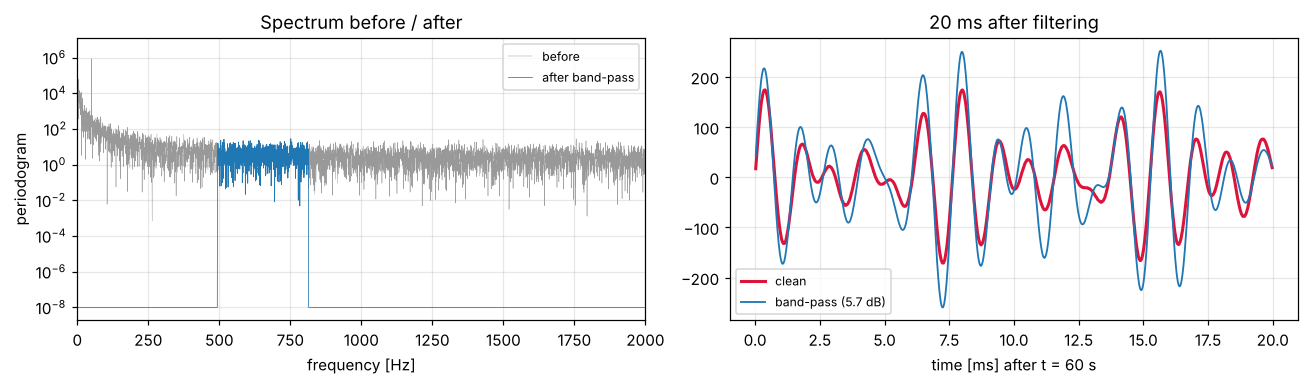

band-pass 493–814 Hz               SNR =    5.7 dB
band-pass 20–814 Hz (hum kept)     SNR =   -8.5 dB


In [9]:
f = rfftfreq(N, 1 / fs)
X = rfft(x)
results = {}                                    # name -> (filter H, output y)

def apply(H, name):
    y = irfft(H * X, n=N)                       # n=N: needed for odd N
    results[name] = (H, y)
    return y

y_bp = apply(((f > 493) & (f < 814)).astype(float), 'band-pass 493–814 Hz')
y_bp20 = apply(((f > 20) & (f < 814)).astype(float), 'band-pass 20–814 Hz (hum kept)')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
Pb = np.abs(rfft(y_bp))**2 * 2 / (fs * N)
ax[0].semilogy(f[::50], (np.abs(X)**2 * 2 / (fs * N))[::50], lw=0.3, color='0.6', label='before')
ax[0].semilogy(f[::50], Pb[::50] + 1e-8, lw=0.5, label='after band-pass')
ax[0].set(xlim=(0, 2000), xlabel='frequency [Hz]', ylabel='periodogram', title='Spectrum before / after')
ax[0].legend(fontsize=8)
ax[1].plot(t_ms, s[z], color='crimson', lw=2, label='clean')
ax[1].plot(t_ms, y_bp[z], lw=1.2, label=f'band-pass ({snr_db(y_bp, s):.1f} dB)')
ax[1].set(xlabel='time [ms] after t = 60 s', title='20 ms after filtering'); ax[1].legend(fontsize=8)
savefig('b08_bandpass')
for k in results:
    print(f"{k:<34} SNR = {snr_db(results[k][1], s):6.1f} dB")

## Block 9 — A comb around the lines: width of the teeth (table + plot)

half-width df [Hz]  bins kept  SNR [dB]


                50      35998       5.9


                10       7197      12.9


               2.5       1797      19.2


               0.5        357      26.1
               0.1         71      32.5


              0.01          9      43.2


comb with a tooth at 50 Hz: SNR = -2.0 dB (the hum comes back)


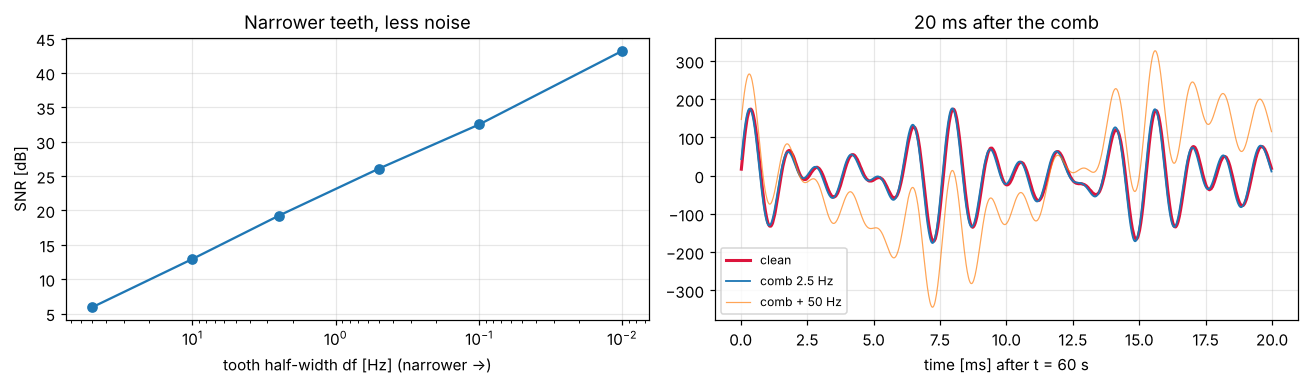

In [10]:
def comb(centres, df):
    H = np.zeros(f.size)
    for fl in centres:
        H[np.abs(f - fl) < df] = 1.0
    return H

print(f"{'half-width df [Hz]':>18} {'bins kept':>10} {'SNR [dB]':>9}")
dfs = [50, 10, 2.5, 0.5, 0.1, 0.01]
snrs = []
for df in dfs:
    H = comb(lines, df)
    y = irfft(H * X, n=N)
    snrs.append(snr_db(y, s))
    print(f"{df:18g} {int(H.sum()):10d} {snrs[-1]:9.1f}")
y_comb = apply(comb(lines, 2.5), 'comb, 2.5 Hz teeth')
y_combhum = apply(comb(lines_all, 2.5), 'comb 2.5 Hz + tooth at 50 Hz')
print(f"comb with a tooth at 50 Hz: SNR = {snr_db(y_combhum, s):.1f} dB (the hum comes back)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].semilogx(dfs, snrs, 'o-'); ax[0].invert_xaxis()
ax[0].set(xlabel='tooth half-width df [Hz] (narrower →)', ylabel='SNR [dB]', title='Narrower teeth, less noise')
ax[1].plot(t_ms, s[z], color='crimson', lw=2, label='clean')
ax[1].plot(t_ms, y_comb[z], lw=1.2, label='comb 2.5 Hz')
ax[1].plot(t_ms, y_combhum[z], lw=0.8, alpha=0.7, label='comb + 50 Hz')
ax[1].set(xlabel='time [ms] after t = 60 s', title='20 ms after the comb'); ax[1].legend(fontsize=8)
savefig('b09_comb')

## Block 10 — Fit the noise spectrum (three parameters, in logarithms)

fit                                    A   fk [Hz]   alpha
all points                         3.072     457.3   1.983
lines excluded                     3.073     439.4   2.007
log bins, lines excluded           3.111     420.6   2.041
generator (truth)                            440.0   2.000
1-sigma errors (lines excluded): ln A ±0.0005, ln fk ±0.0025, alpha ±0.0032  (statistical only)
rms of the log residuals: 0.079


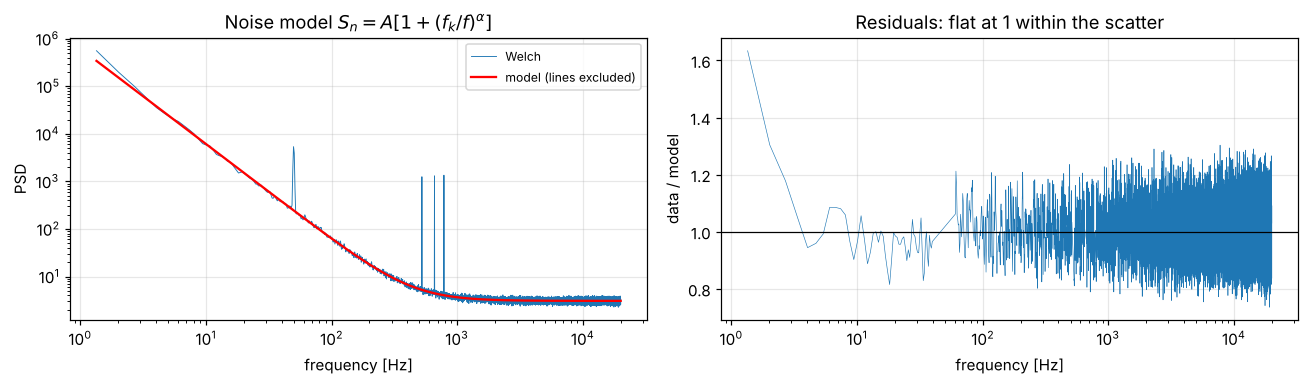

In [11]:
def logS(f, lA, lfk, alpha):                       # ln S_n, with A = e^lA, fk = e^lfk
    return lA + np.log1p((np.exp(lfk) / f)**alpha)

sel = (fw >= 1) & (fw <= 20000)
far = np.all(np.abs(fw[:, None] - np.array(lines_all)) > 10, axis=1)
p_all, _ = curve_fit(logS, fw[sel], np.log(W[sel]), p0=[np.log(10), np.log(300), 1.5])
p, cov = curve_fit(logS, fw[sel & far], np.log(W[sel & far]), p0=[np.log(10), np.log(300), 1.5])
err = np.sqrt(np.diag(cov))
# log-binned version: equal weight per decade
edges = np.logspace(0, np.log10(20000), 61)
idx = np.digitize(fw, edges)
fb_, Wb_ = [], []
for i in range(1, 61):
    m = (idx == i) & sel & far
    if m.sum():
        fb_.append(np.exp(np.mean(np.log(fw[m])))); Wb_.append(np.exp(np.mean(np.log(W[m]))))
p_bin, _ = curve_fit(logS, np.array(fb_), np.log(Wb_), p0=p)

print(f"{'fit':<32}{'A':>8}{'fk [Hz]':>10}{'alpha':>8}")
for name, q in [('all points', p_all), ('lines excluded', p), ('log bins, lines excluded', p_bin)]:
    print(f"{name:<32}{np.exp(q[0]):8.3f}{np.exp(q[1]):10.1f}{q[2]:8.3f}")
print(f"{'generator (truth)':<32}{'':>8}{440.0:10.1f}{2.0:8.3f}")
print(f"1-sigma errors (lines excluded): ln A ±{err[0]:.4f}, ln fk ±{err[1]:.4f}, alpha ±{err[2]:.4f}  (statistical only)")
resid = np.log(W[sel & far]) - logS(fw[sel & far], *p)
print(f"rms of the log residuals: {resid.std():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].loglog(fw[sel], W[sel], lw=0.6, label='Welch')
ax[0].loglog(fw[sel], np.exp(logS(fw[sel], *p)), 'r', lw=1.5, label='model (lines excluded)')
ax[0].set(xlabel='frequency [Hz]', ylabel='PSD', title='Noise model $S_n=A[1+(f_k/f)^α]$'); ax[0].legend(fontsize=8)
ax[1].semilogx(fw[sel & far], W[sel & far] / np.exp(logS(fw[sel & far], *p)), lw=0.4)
ax[1].axhline(1, color='k', lw=0.8)
ax[1].set(xlabel='frequency [Hz]', ylabel='data / model', title='Residuals: flat at 1 within the scatter')
savefig('b10_noise_fit')

## Block 11 — Wiener filter, naive version (every bin)

fraction of noise-only bins with z > 1: 0.369  (theory e^-1 = 0.368)
SNR of the naive Wiener output: -37.5 dB


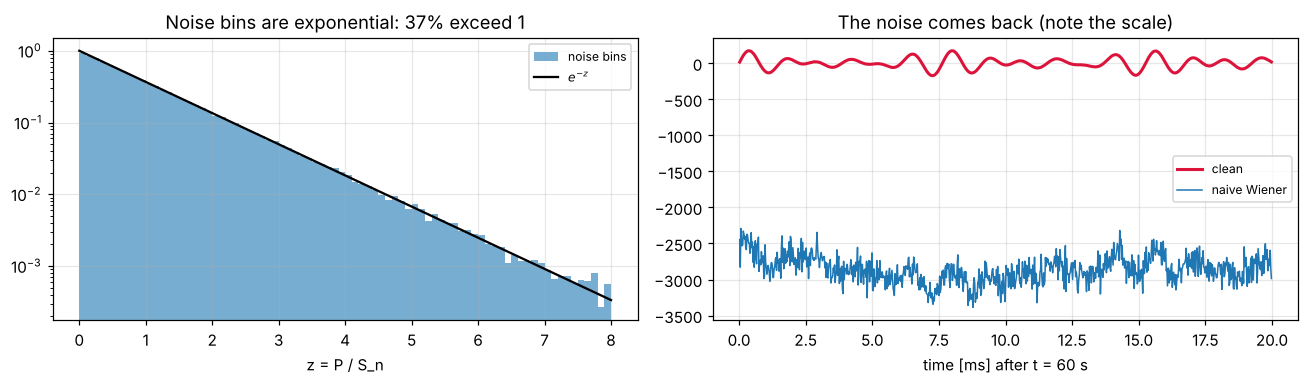

In [12]:
Pk = np.abs(X)**2 * 2 / (fs * N)                    # periodogram in density units (= sp.periodogram)
Sn = np.exp(logS(np.maximum(f, 1e-3), *p))          # noise model at every frequency
z_snr = Pk / Sn                                      # how many times the data exceed the noise
phi = np.clip(1 - 1 / z_snr, 0, 1)                   # Wiener weight Phi = 1 - 1/z
y_naive = apply(phi, 'Wiener, naive (all bins)')

noise_bins = (f > 20) & np.all(np.abs(f[:, None] - np.array(lines_all)) > 2, axis=1)
print(f"fraction of noise-only bins with z > 1: {np.mean(z_snr[noise_bins] > 1):.3f}  (theory e^-1 = {np.exp(-1):.3f})")
print(f"SNR of the naive Wiener output: {snr_db(y_naive, s):.1f} dB")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
zz = z_snr[noise_bins][::7]
ax[0].hist(zz, bins=np.linspace(0, 8, 81), density=True, alpha=0.6, label='noise bins')
ax[0].plot(np.linspace(0, 8, 200), np.exp(-np.linspace(0, 8, 200)), 'k', label='$e^{-z}$')
ax[0].set(yscale='log', xlabel='z = P / S_n', title='Noise bins are exponential: 37% exceed 1'); ax[0].legend(fontsize=8)
ax[1].plot(t_ms, s[z], color='crimson', lw=2, label='clean')
ax[1].plot(t_ms, y_naive[z], lw=1, label='naive Wiener')
ax[1].set(xlabel='time [ms] after t = 60 s', title='The noise comes back (note the scale)'); ax[1].legend(fontsize=8)
savefig('b11_wiener_naive')

## Block 12 — Wiener filter on the detected lines (threshold z*, hum removed)

M = 2643600 bins tested, z* = ln(M/0.01) = 19.4; largest noise-only z = 15.3
   f [Hz]         z  amplitude 2|X|/N   nature
   50.000      3544             120.1   mains hum: vetoed
  523.300     41349              60.1   C5 (+0 cents)
  659.300     48722              60.0   E5 (+0 cents)
  784.000     53536              60.0   G5 (+0 cents)


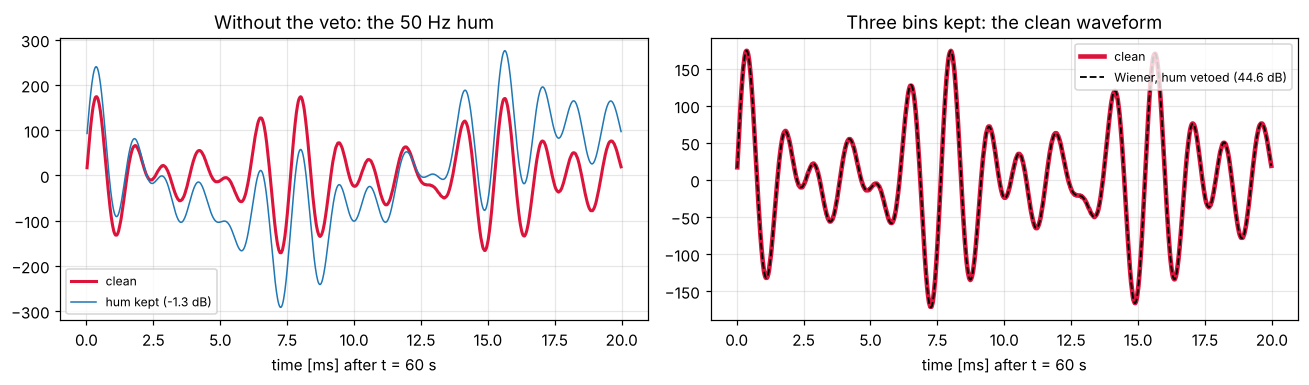

In [13]:
M = np.sum(f > 20)                                   # bins tested
zstar = np.log(M / 0.01)                             # one false line in 100 recordings
det_all = (z_snr > zstar) & (f > 20)
det = det_all & (np.abs(f - HUM) > 0.5)              # veto the mains hum
print(f"M = {M} bins tested, z* = ln(M/0.01) = {zstar:.1f}; largest noise-only z = {z_snr[noise_bins].max():.1f}")
print(f"{'f [Hz]':>9} {'z':>9} {'amplitude 2|X|/N':>17}   nature")
for k in np.flatnonzero(det_all):
    kind = 'mains hum: vetoed' if abs(f[k] - HUM) < 1 else note_name(f[k])
    print(f"{f[k]:9.3f} {z_snr[k]:9.0f} {2 * np.abs(X[k]) / N:17.1f}   {kind}")
y_wien = apply(np.where(det, phi, 0.0), 'Wiener, detected lines (hum vetoed)')
y_wienhum = apply(np.where(det_all, phi, 0.0), 'Wiener, detected lines (hum kept)')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(t_ms, s[z], color='crimson', lw=2, label='clean')
ax[0].plot(t_ms, y_wienhum[z], lw=1, label=f'hum kept ({snr_db(y_wienhum, s):.1f} dB)')
ax[0].set(xlabel='time [ms] after t = 60 s', title='Without the veto: the 50 Hz hum'); ax[0].legend(fontsize=8)
ax[1].plot(t_ms, s[z], color='crimson', lw=3, label='clean')
ax[1].plot(t_ms, y_wien[z], 'k--', lw=1.2, label=f'Wiener, hum vetoed ({snr_db(y_wien, s):.1f} dB)')
ax[1].set(xlabel='time [ms] after t = 60 s', title='Three bins kept: the clean waveform'); ax[1].legend(fontsize=8)
savefig('b12_wiener_lines')

## Block 13 — Whittle fit of the noise on the periodogram

In [14]:
def whittle(mask, start):
    fs_, Ps = f[mask], Pk[mask]
    def nll(q):
        S = np.exp(logS(fs_, *q))
        return np.sum(np.log(S) + Ps / S)
    return minimize(nll, start, method='Nelder-Mead', options=dict(xatol=1e-6, fatol=1e-3, maxiter=2000)).x

base = (f >= 1) & (f <= 20000)
far2 = np.all(np.abs(f[:, None] - np.array(lines_all)) > 2, axis=1)
q_all = whittle(base, p)
q_far = whittle(base & far2, p)
print(f"{'estimator':<40}{'A':>8}{'fk [Hz]':>10}{'alpha':>8}")
for name, q in [('least squares on log Welch (lines out)', p), ('Whittle, all bins', q_all),
                ('Whittle, lines excluded', q_far)]:
    print(f"{name:<40}{np.exp(q[0]):8.3f}{np.exp(q[1]):10.1f}{q[2]:8.3f}")
print(f"{'generator (truth)':<40}{'':>8}{440.0:10.1f}{2.0:8.3f}")

estimator                                      A   fk [Hz]   alpha
least squares on log Welch (lines out)     3.073     439.4   2.007
Whittle, all bins                          2.977     936.4   1.604
Whittle, lines excluded                    3.078     442.7   1.994
generator (truth)                                    440.0   2.000


## Block 14 — Summary of all filters on recording 1 (table, plots, listening)

filter                                   bins kept  SNR [dB]  residual rms
--------------------------------------------------------------------------
no filter (the data)                       2646001     -45.1       13193.8


band-pass 493–814 Hz                         38519       5.7          38.2


band-pass 20–814 Hz (hum kept)               95279      -8.5         196.3
comb, 2.5 Hz teeth                            1797      19.2           8.0


comb 2.5 Hz + tooth at 50 Hz                  2396      -2.0          92.1


Wiener, naive (all bins)                    976472     -37.5        5521.7
Wiener, detected lines (hum vetoed)              3      44.6           0.4


Wiener, detected lines (hum kept)                4      -1.3          84.9


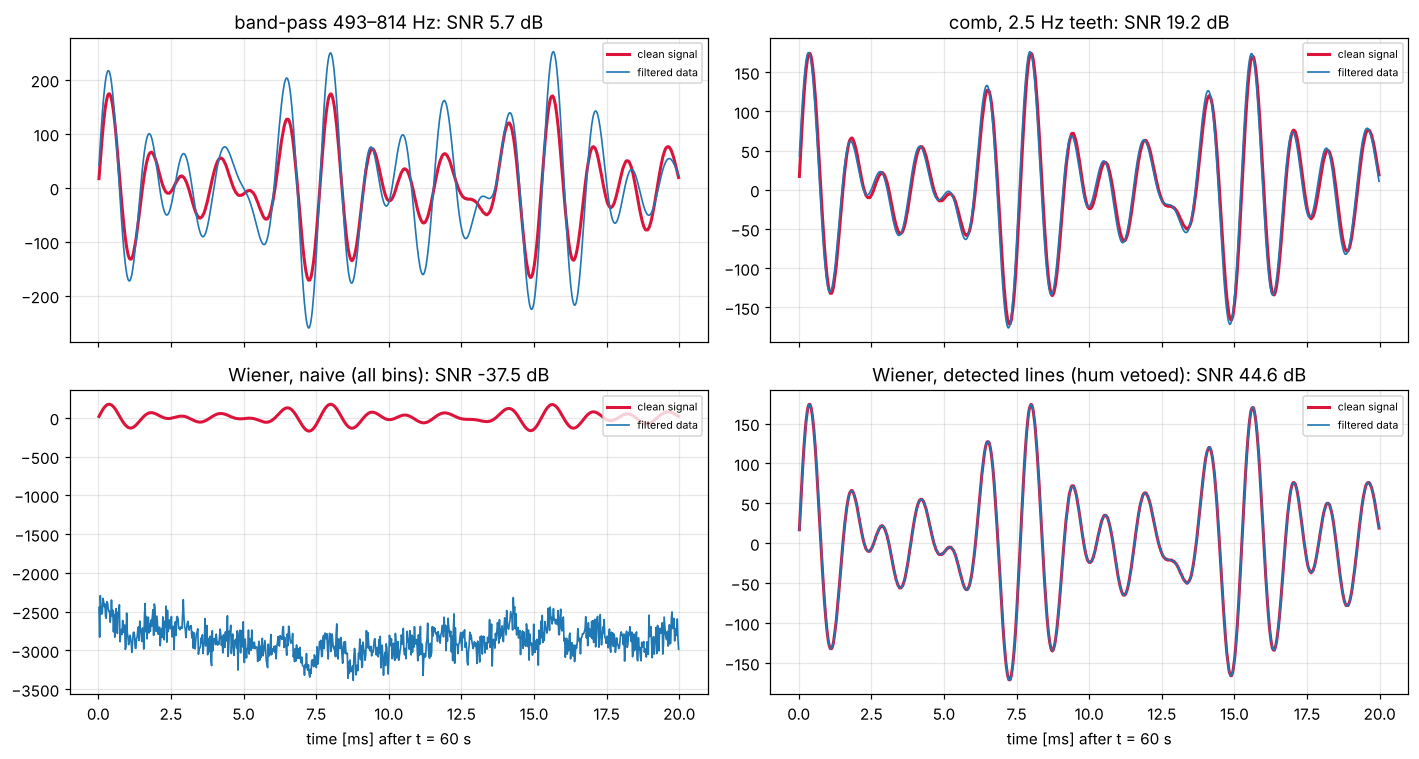

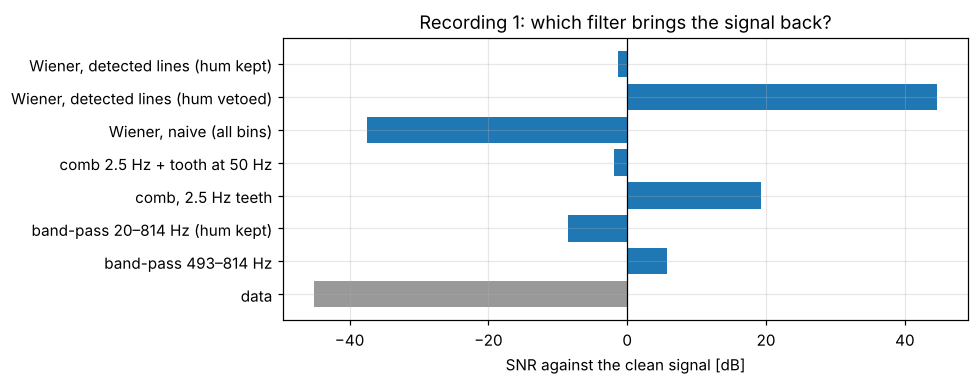

noisy data


clean signal


band-pass 493–814 Hz


comb, 2.5 Hz teeth


Wiener, naive (all bins)


Wiener, detected lines (hum vetoed)


In [15]:
print(f"{'filter':<40}{'bins kept':>10}{'SNR [dB]':>10}{'residual rms':>14}")
print('-' * 74)
print(f"{'no filter (the data)':<40}{N//2+1:>10}{snr_db(x - x.mean(), s):10.1f}{np.std(x - s):14.1f}")
for name, (H, y) in results.items():
    print(f"{name:<40}{int(np.count_nonzero(H)):>10}{snr_db(y, s):10.1f}{np.std(y - s):14.1f}")

show = ['band-pass 493–814 Hz', 'comb, 2.5 Hz teeth', 'Wiener, naive (all bins)', 'Wiener, detected lines (hum vetoed)']
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, name in zip(axes.flat, show):
    y = results[name][1]
    ax.plot(t_ms, s[z], color='crimson', lw=2, label='clean signal')
    ax.plot(t_ms, y[z], lw=1.1, label='filtered data')
    ax.set_title(f'{name}: SNR {snr_db(y, s):.1f} dB'); ax.legend(fontsize=7, loc='upper right')
for ax in axes[1]: ax.set_xlabel('time [ms] after t = 60 s')
savefig('b14_filters_2x2')

plt.figure(figsize=(9, 3.6))
names = ['data'] + list(results)
vals = [snr_db(x - x.mean(), s)] + [snr_db(results[k][1], s) for k in results]
plt.barh(names, vals, color=['0.6'] + ['tab:blue'] * len(results)); plt.axvline(0, color='k', lw=0.8)
plt.xlabel('SNR against the clean signal [dB]'); plt.title('Recording 1: which filter brings the signal back?')
savefig('b14_snr_bar')

# save full recordings and 5 s clips (60–65 s) to listen to
clip = slice(int(60 * fs), int(65 * fs))
write_wav('rec1_noisy.wav', x - x.mean(), fs); write_wav('rec1_clean.wav', s, fs)
for k, name in enumerate(show, 1):
    write_wav(f'rec1_filter{k}.wav', results[name][1], fs)
if IN_COLAB or True:
    from IPython.display import Audio, display
    for title, y in [('noisy data', x - x.mean()), ('clean signal', s)] + [(n, results[n][1]) for n in show]:
        print(title); display(Audio(y[clip], rate=fs, normalize=True))   # only 5 s: a light notebook

## Block 15 — Recording 2: two lines 2 Hz apart (resolution, beat, filters)

window, L              bin [Hz]  dip/peak 440-442


nuttall, 2^16             0.673              0.45


flattop, 2^16             0.673              1.00


nuttall, 2^17             0.336              0.00


nuttall, 2^18             0.168              0.00
STFT 0.1 s: modulation depth of the 436-446 Hz power = 1.00


STFT 2.0 s: modulation depth of the 436-446 Hz power = 0.15


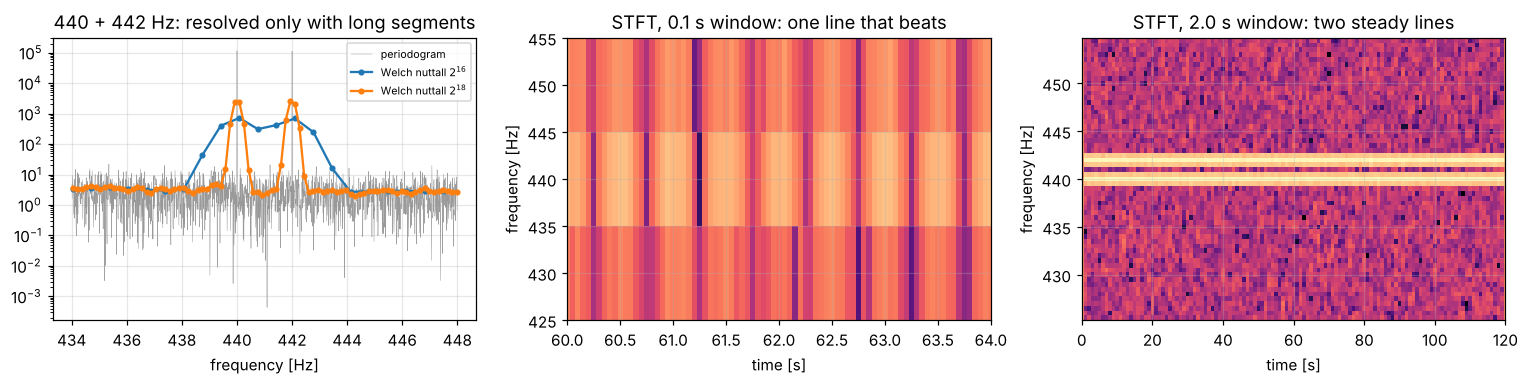

noise fit, recording 2: A = 1.64, fk = 437.9 Hz, alpha = 2.017
detected lines [Hz]: 440.000 (A4 (+0 cents)), 442.000 (A4 (+8 cents)), 880.000 (A5 (+0 cents))
filter (recording 2)                      SNR [dB]


band-pass 400–920 Hz                           3.4
comb 2.5 Hz (one band for 440+442)            19.6


Wiener, detected lines (hum vetoed)           41.8


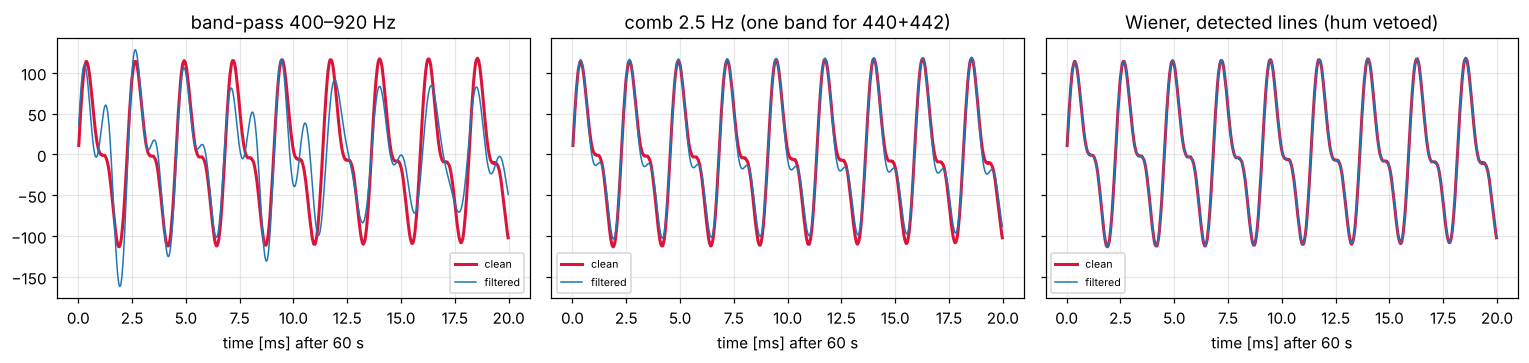

In [16]:
fs2, x2 = read_wav('dati_rumorosi_2.wav')
_, s2 = read_wav('segnale_2.wav')
N2 = x2.size; t2 = np.arange(N2) / fs2
f2 = rfftfreq(N2, 1 / fs2); X2 = rfft(x2)
lines2 = [440.0, 442.0, 880.0]
lines2_all = [HUM] + lines2

# resolving 440 and 442 Hz: dip between the peaks / smaller peak
print(f"{'window, L':<22}{'bin [Hz]':>9}{'dip/peak 440-442':>18}")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
fp2, P2 = sp.periodogram(x2, fs2)
m = (fp2 > 434) & (fp2 < 448)
ax[0].semilogy(fp2[m], P2[m], lw=0.3, color='0.6', label='periodogram')
for win, q in [('nuttall', 16), ('flattop', 16), ('nuttall', 17), ('nuttall', 18)]:
    fq, Wq = sp.welch(x2, fs2, window=win, nperseg=2**q)
    mm = (fq > 434) & (fq < 448)
    i1, i2 = np.argmin(np.abs(fq - 440)), np.argmin(np.abs(fq - 442))
    dip = Wq[i1:i2 + 1].min() / min(Wq[i1], Wq[i2])
    print(f"{win + ', 2^' + str(q):<22}{fs2 / 2**q:9.3f}{dip:18.2f}")
    if win == 'nuttall' and q in (16, 18):
        ax[0].semilogy(fq[mm], Wq[mm], 'o-', ms=3, label=f'Welch nuttall $2^{{{q}}}$')
ax[0].set(xlabel='frequency [Hz]', title='440 + 442 Hz: resolved only with long segments'); ax[0].legend(fontsize=7)

for a, Lsec in zip(ax[1:], [0.1, 2.0]):
    nps = int(Lsec * fs2)
    fq, tt, Zq = sp.stft(x2, fs2, window='hann', nperseg=nps, noverlap=nps // 2)
    bnd = (fq > 425) & (fq < 455)
    a.pcolormesh(tt, fq[bnd], 10 * np.log10(np.abs(Zq[bnd])**2 + 1e-12), shading='auto', cmap='magma')
    a.set(xlim=(60, 64) if Lsec < 1 else (0, 120), xlabel='time [s]', ylabel='frequency [Hz]',
          title=f'STFT, {Lsec} s window: ' + ('one line that beats' if Lsec < 1 else 'two steady lines'))
    pw = (np.abs(Zq[(fq > 436) & (fq < 446)])**2).sum(0)[2:-2]
    print(f"STFT {Lsec} s: modulation depth of the 436-446 Hz power = {(pw.max() - pw.min()) / (pw.max() + pw.min()):.2f}")
savefig('b15_rec2_resolution')

# noise fit, detection and filters on recording 2
fw2, W2 = sp.welch(x2, fs2, window='nuttall', nperseg=2**16)
sel2 = (fw2 >= 1) & (fw2 <= 20000) & np.all(np.abs(fw2[:, None] - np.array(lines2_all)) > 10, axis=1)
p2, _ = curve_fit(logS, fw2[sel2], np.log(W2[sel2]), p0=[np.log(10), np.log(300), 1.5])
print(f"noise fit, recording 2: A = {np.exp(p2[0]):.2f}, fk = {np.exp(p2[1]):.1f} Hz, alpha = {p2[2]:.3f}")
Pk2 = np.abs(X2)**2 * 2 / (fs2 * N2)
z2 = Pk2 / np.exp(logS(np.maximum(f2, 1e-3), *p2))
phi2 = np.clip(1 - 1 / z2, 0, 1)
det2 = (z2 > np.log(np.sum(f2 > 20) / 0.01)) & (f2 > 20) & (np.abs(f2 - HUM) > 0.5)
print('detected lines [Hz]:', ', '.join(f'{v:.3f} ({note_name(v)})' for v in f2[det2]))

comb2 = np.zeros(f2.size)
for fl in lines2:
    comb2[np.abs(f2 - fl) < 2.5] = 1.0
res2 = {'band-pass 400–920 Hz': ((f2 > 400) & (f2 < 920)).astype(float),
        'comb 2.5 Hz (one band for 440+442)': comb2,
        'Wiener, detected lines (hum vetoed)': np.where(det2, phi2, 0.0)}
zz2 = (t2 > 60) & (t2 < 60.02)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
print(f"{'filter (recording 2)':<40}{'SNR [dB]':>10}")
for a, (name, H) in zip(ax, res2.items()):
    y2 = irfft(H * X2, n=N2)
    res2[name] = (H, y2)
    print(f"{name:<40}{snr_db(y2, s2):10.1f}")
    a.plot((t2[zz2] - 60) * 1e3, s2[zz2], color='crimson', lw=2, label='clean')
    a.plot((t2[zz2] - 60) * 1e3, y2[zz2], lw=1, label='filtered')
    a.set(title=f'{name}', xlabel='time [ms] after 60 s'); a.legend(fontsize=7)
savefig('b15_rec2_filters')
write_wav('rec2_noisy.wav', x2 - x2.mean(), fs2)
write_wav('rec2_comb.wav', res2['comb 2.5 Hz (one band for 440+442)'][1], fs2)

## Block 16 — Conclusions and list of corrections

**What the analysis shows** (numbers printed above):
1. The signal is invisible in the samples (−45 dB below the noise) but stands ~10⁴–10⁵ above the noise in single periodogram bins:
   three steady lines put all their power in one bin of 1/T = 0.008 Hz.
2. Welch shows the *noise* (red, ∝ f⁻² below a knee at ≈ 440 Hz, white above); the periodogram shows the *lines*. The window matters:
   the rectangular window leaks the red noise upwards (×2 at 50–100 Hz).
3. Recording 1 is a C major chord (C5, E5, G5); recording 2 is A4, A4 + 8 cents and A5. 440 and 442 Hz are resolved only with
   segments longer than ~2 s; with short windows they are one tone beating twice per second.
4. Filters: the band-pass brings the chord back with some hiss; narrower comb teeth give higher SNR; the naive Wiener filter fails
   (37% of noise bins exceed the model); Wiener on the *detected* lines, with the 50 Hz hum vetoed, returns the clean waveform.
5. The noise fit recovers the generator (f_k ≈ 440 Hz, α ≈ 2); Whittle is the best estimator once the lines are excluded.

**Corrections to the original notebook (`AstroSignal.ipynb`)**
- `np.abs(x).max` printed a method object → `np.abs(x).max()`.
- `fs, s = wavfile.read('data/segnale.wav')` silently overwrote `fs` → separate name and an `assert`.
- Cells 8–13 had never been run (no outputs) and one cell was empty → the whole chain now runs top to bottom.
- Plots had no axis labels, units, titles or legends → added everywhere; every figure is also saved in `figures/`.
- Step 1 compared windows only by eye → tables of leakage and line contrast (Blocks 5–6) and automatic line finding (Block 4).
- Stationarity was not quantified → amplitude of each line in 10 s blocks (Block 7).
- Comb width not explored → SNR against the tooth width (Block 9).
- Noise fit and Wiener filter were only coded for recording 1 and printed whole arrays → tables, residual plots and recording 2 (Block 15).
- The audio cell embedded the full 120 s WAVs (≈10 MB each) while saying "first 5 seconds" → 5 s clips.
- Colab-only upload cell → works in Colab and locally.